In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()
x_train, x_test = x_train[:4000] / 255.0, x_test[:1000] / 255.0
y_train, y_test = y_train[:4000], y_test[:1000]

configs = [
    ("2 Conv + MaxPool", [32, 64], layers.MaxPooling2D, False, 3),
    ("3 Conv + AvgPool", [32, 64, 64], layers.AveragePooling2D, False, 3),
    ("4 Conv + BN + MaxPool", [32, 64, 64, 128], layers.MaxPooling2D, True, 3),
]

names, accs, times, params = [], [], [], []
for name, filters, pool_fn, use_bn, k in configs:
    model = models.Sequential([layers.Input(shape=(32, 32, 3))])
    for f in filters:
        model.add(layers.Conv2D(f, (k, k), padding="same", activation="relu"))
        if use_bn:
            model.add(layers.BatchNormalization())
        if model.output_shape[1] >= 4:
            model.add(pool_fn((2, 2)))
    model.add(layers.Flatten())
    model.add(layers.Dense(64, activation="relu"))
    model.add(layers.Dense(10, activation="softmax"))

    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    t0 = time.time()
    model.fit(x_train, y_train, epochs=3, batch_size=64, verbose=0)
    elapsed = time.time() - t0
    _, acc = model.evaluate(x_test, y_test, verbose=0)

    names.append(name); accs.append(acc * 100)
    times.append(elapsed); params.append(model.count_params() / 1e3)
    print(f"{name:22s} | Acc: {acc*100:5.2f}% | Params: {model.count_params():7d} | Time: {elapsed:.2f}s")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(names, accs, color="steelblue")
axes[0].set_title("Test Accuracy (%)"); axes[0].tick_params(axis="x", rotation=15)
axes[1].bar(names, params, color="coral")
axes[1].set_title("Parameters (Thousands)"); axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

 79929344/170498071 ━━━━━━━━━━━━━━━━━━━━ 7:20 5us/step

KeyboardInterrupt: 

2 Conv + MaxPool       | Acc:  9.00% | Params:  282250 | Time: 4.53s
3 Conv + AvgPool       | Acc:  8.50% | Params:  122570 | Time: 6.42s
4 Conv + BN + MaxPool  | Acc:  8.00% | Params:  164810 | Time: 8.27s


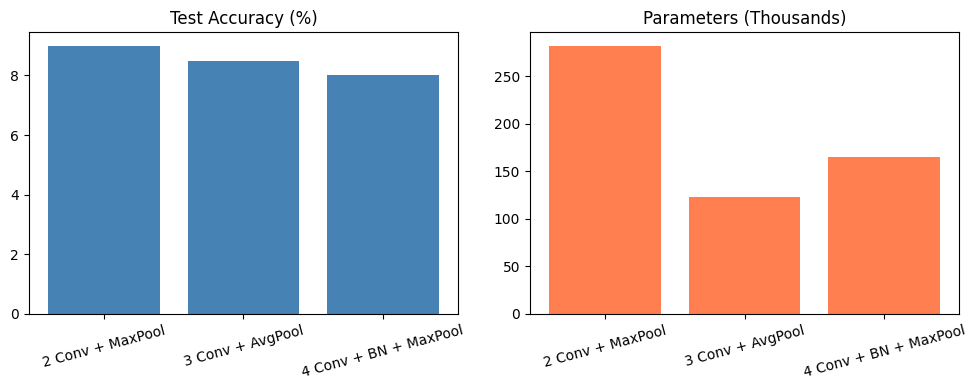

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

rng = np.random.default_rng(42)
x_train = rng.random((800, 32, 32, 3), dtype=np.float32)
y_train = rng.integers(0, 10, size=(800, 1))
x_test = rng.random((200, 32, 32, 3), dtype=np.float32)
y_test = rng.integers(0, 10, size=(200, 1))

configs = [
    ("2 Conv + MaxPool", [32, 64], layers.MaxPooling2D, False, 3),
    ("3 Conv + AvgPool", [32, 64, 64], layers.AveragePooling2D, False, 3),
    ("4 Conv + BN + MaxPool", [32, 64, 64, 128], layers.MaxPooling2D, True, 3),
]

names, accs, params = [], [], []
for name, filters, pool_fn, use_bn, k in configs:
    model = models.Sequential([layers.Input(shape=(32, 32, 3))])
    for f in filters:
        model.add(layers.Conv2D(f, (k, k), padding="same", activation="relu"))
        if use_bn:
            model.add(layers.BatchNormalization())
        if model.output_shape[1] >= 4:
            model.add(pool_fn((2, 2)))
    model.add(layers.Flatten())
    model.add(layers.Dense(64, activation="relu"))
    model.add(layers.Dense(10, activation="softmax"))

    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    t0 = time.time()
    model.fit(x_train, y_train, epochs=2, batch_size=64, verbose=0)
    _, acc = model.evaluate(x_test, y_test, verbose=0)

    names.append(name); accs.append(acc * 100); params.append(model.count_params() / 1e3)
    print(f"{name:22s} | Acc: {acc*100:5.2f}% | Params: {model.count_params():7d} | Time: {time.time()-t0:.2f}s")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(names, accs, color="steelblue")
axes[0].set_title("Test Accuracy (%)"); axes[0].tick_params(axis="x", rotation=15)
axes[1].bar(names, params, color="coral")
axes[1].set_title("Parameters (Thousands)"); axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()